# 03 – A projekt újraértékelése és a vizsgálati irány módosítása

## A notebook célja

Az első adat-migráció után értékeljük, hogy az eredeti elképzelés – a vízállás és a vízhőmérséklet együttes elemzése – milyen mértékben használja fel a rendelkezésre álló adatokat.

A korábbi, fájlonkénti adatminőségi összesítő alapján a tíz CSV-fájlban összesen **221 805 vízállásrekord** szerepel. Ezek közül a vízhőmérséklet mindössze **2 395 rekordnál** áll rendelkezésre, ami körülbelül **1,08%**.

Ez az előzetes arány a fájlonkénti összesítőből származik. Ebben a notebookban a 02-es migráció eredményeiből újraszámítjuk a tényleges, mindhárom érvényes adattal rendelkező rekordok arányát is.

## A módszertani döntés

A vízhőmérsékleti adatok ilyen mértékű hiánya mellett a vízállás és a vízhőmérséklet együttes vizsgálata a teljes időszakra nem biztosít megfelelő adatmennyiséget és időbeli lefedettséget.

Ezért a projekt fő elemzési irányát módosítjuk:

**A továbbiakban a 2016–2026 közötti időszak teljes, érvényes vízállás-adatállományára koncentrálunk, a vízhőmérsékleti adatoktól függetlenül.**

A vízhőmérsékleti adatok nem vesznek el: az eredeti CSV-fájlokban és az első migráció szűrés előtti állományában megmaradnak. Később külön, korlátozott lefedettségű vizsgálatra még felhasználhatók.


## 1. Projektkönyvtár és a 02-es migráció eredményeinek beolvasása

A notebook a 02-es migrációban létrehozott két fájlt használja:
- a szűrés előtti, összevont adatállományt;
- a vízhőmérsékletet is megkövetelő, szűrt adatállományt.

A fájlokat nem módosítjuk.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    r"C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT"
)

INTERIM_FILE = (
    PROJECT_DIR / "data" / "interim" /
    "balaton_2016-2026_osszesitett_szures_elott.csv"
)
FILTERED_FILE = (
    PROJECT_DIR / "data" / "processed" /
    "balaton_2016-2026_vizallas_vizho_ervenyes.csv"
)
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

for file_path in [INTERIM_FILE, FILTERED_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Nem található a 02-es migráció kimeneti fájlja: {file_path}\n"
            "Először futtasd végig a 02_initial_data_migration.ipynb notebookot."
        )

all_records = pd.read_csv(
    INTERIM_FILE, sep=";", encoding="utf-8-sig",
    parse_dates=["idopont"]
)
temperature_valid_records = pd.read_csv(
    FILTERED_FILE, sep=";", encoding="utf-8-sig",
    parse_dates=["idopont"]
)

print("Összes beolvasott rekord:", f"{len(all_records):,}")
print("Mindhárom érvényes adattal rendelkező rekord:", f"{len(temperature_valid_records):,}")


Összes beolvasott rekord: 221,805
Mindhárom érvényes adattal rendelkező rekord: 2,392


## 2. Az adatok felhasználhatóságának összehasonlítása

A teljes adatmennyiséget a szűrés előtti, összevont állomány rekordjai jelentik. Az együttes vízállás–vízhőmérséklet-vizsgálatra felhasználható adatmennyiséget a 02-es migrációban megtartott rekordok jelentik.

A két érték arányából kiszámítjuk, hogy a teljes adatmennyiség hány százaléka marad meg a vízhőmérséklet megkövetelése esetén.


In [2]:
total_count = len(all_records)
joint_count = len(temperature_valid_records)
excluded_count = total_count - joint_count

joint_share = (joint_count / total_count * 100) if total_count else np.nan

comparison = pd.DataFrame([
    {
        "adatállomány": "Összes vízállásrekord (szűrés előtt)",
        "rekordok_száma": total_count,
        "teljes_adatmennyiség_%-a": 100.0
    },
    {
        "adatállomány": "Vízállás és vízhőmérséklet együtt (szűrés után)",
        "rekordok_száma": joint_count,
        "teljes_adatmennyiség_%-a": joint_share
    },
    {
        "adatállomány": "A vízhőmérséklet hiánya miatt nem megtartott rekordok",
        "rekordok_száma": excluded_count,
        "teljes_adatmennyiség_%-a": (
            excluded_count / total_count * 100 if total_count else np.nan
        )
    }
])

display(
    comparison.style.format({
        "rekordok_száma": "{:,.0f}",
        "teljes_adatmennyiség_%-a": "{:.2f}%"
    })
)

print(f"A szűrt állomány aránya: {joint_share:.2f}%")


,adatállomány,rekordok_száma,teljes_adatmennyiség_%-a
0,Összes vízállásrekord (szűrés előtt),"221,805",100.00%
1,Vízállás és vízhőmérséklet együtt (szűrés után),"2,392",1.08%
2,A vízhőmérséklet hiánya miatt nem megtartott rekordok,"219,413",98.92%


A szűrt állomány aránya: 1.08%


## 3. Éves adatmennyiségek összehasonlítása

A fájlonkénti összehasonlítás megmutatja, hogy az együttes vizsgálatra alkalmas rekordok hogyan oszlanak meg az egyes forrásfájlok között.

Az időszak megnevezését a `forras_fajl` oszlopból vesszük át.


In [3]:
def period_from_filename(value):
    return Path(str(value)).stem

all_by_file = (
    all_records.groupby("forras_fajl")
    .size()
    .rename("összes_vízállásrekord")
)

joint_by_file = (
    temperature_valid_records.groupby("forras_fajl")
    .size()
    .rename("mindkét_változóval_érvényes")
)

yearly_comparison = pd.concat([all_by_file, joint_by_file], axis=1).fillna(0)
yearly_comparison["mindkét_változóval_érvényes"] = (
    yearly_comparison["mindkét_változóval_érvényes"].astype(int)
)
yearly_comparison["megtartott_arány_%"] = (
    yearly_comparison["mindkét_változóval_érvényes"]
    / yearly_comparison["összes_vízállásrekord"] * 100
)
yearly_comparison["időszak"] = [
    period_from_filename(name) for name in yearly_comparison.index
]
yearly_comparison = yearly_comparison.reset_index(names="forrásfájl")

display(
    yearly_comparison.style.format({
        "összes_vízállásrekord": "{:,.0f}",
        "mindkét_változóval_érvényes": "{:,.0f}",
        "megtartott_arány_%": "{:.2f}%"
    })
)


,forrásfájl,összes_vízállásrekord,mindkét_változóval_érvényes,megtartott_arány_%,időszak
0,2016-17.csv,"10,681",300,2.81%,2016-17
1,2017-18.csv,"10,341",4,0.04%,2017-18
2,2018-19.csv,"10,380",2,0.02%,2018-19
3,2019-20.csv,"11,068",1,0.01%,2019-20
4,2020-21.csv,"10,664",273,2.56%,2020-21
5,2021-22.csv,"28,186",364,1.29%,2021-22
6,2022-23.csv,"35,109",360,1.03%,2022-23
7,2023-24.csv,"35,209",364,1.03%,2023-24
8,2024-25.csv,"35,122",363,1.03%,2024-25
9,2025-26.csv,"35,045",361,1.03%,2025-26


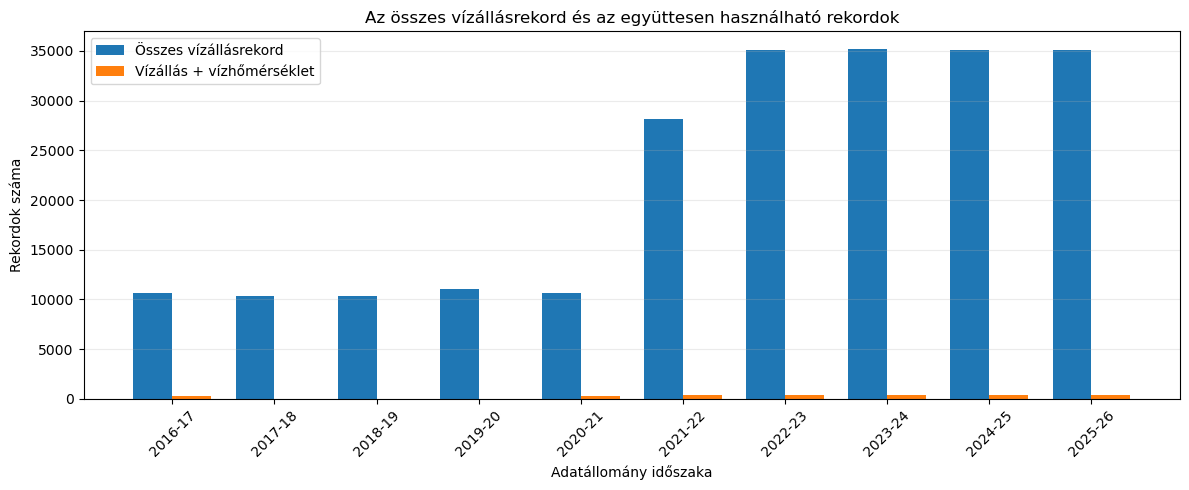

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(yearly_comparison))
width = 0.38

ax.bar(
    x - width / 2,
    yearly_comparison["összes_vízállásrekord"],
    width,
    label="Összes vízállásrekord"
)
ax.bar(
    x + width / 2,
    yearly_comparison["mindkét_változóval_érvényes"],
    width,
    label="Vízállás + vízhőmérséklet"
)

ax.set_title("Az összes vízállásrekord és az együttesen használható rekordok")
ax.set_xlabel("Adatállomány időszaka")
ax.set_ylabel("Rekordok száma")
ax.set_xticks(x)
ax.set_xticklabels(yearly_comparison["időszak"], rotation=45)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 4. A projekt módszertani újraértékelése

A fájlonkénti adatminőségi összesítő szerint a teljes, 221 805 rekordos állományból 2 395 rekord tartalmaz vízhőmérsékleti értéket. Ez előzetesen körülbelül 1,08%-os arányt jelent.

A 02-es migrációból származó pontos arányt a fenti számítás mutatja meg. A ténylegesen megtartott rekordok száma ennél kissé alacsonyabb is lehet, ha a vízállás vagy az időpont egyes rekordokban szintén érvénytelen.

### Meghozott döntés

**A projekt fő elemzési iránya módosul: a továbbiakban a Balaton vízállásának elemzésére koncentrálunk, a vízhőmérsékleti adatok meglététől függetlenül.**

A döntés indokai:
1. A vízhőmérsékletet is megkövetelő szűrés a teljes adatmennyiségnek csak körülbelül 1%-át hagyja meg.
2. A megmaradó adatok időbeli lefedettsége nem megfelelő a teljes, 2016–2026 közötti időszak kiegyensúlyozott vizsgálatához.
3. A vízállás önállóan, lényegesen nagyobb adatmennyiségen elemezhető.
4. A vízhőmérsékleti adatokat nem töröljük, de nem tesszük a fő elemzés feltételévé.

### A döntés következménye

A következő munkafázisban új migrációt készítünk, amely:
- minden érvényes időponttal és vízállással rendelkező rekordot megtart;
- nem követeli meg a vízhőmérséklet meglétét;
- megőrzi a forrásfájl nevét és a forrásrekord sorszámát;
- külön adatállományba menti a teljes vízállás-adatsort.

A vízállás és a vízhőmérséklet kapcsolatát – ha később vizsgáljuk – külön, a ténylegesen együttesen rendelkezésre álló adatokra kell korlátozni.


In [5]:
# A döntéshez használt összesített mutatók mentése.
decision_summary = pd.DataFrame([{
    "összes_vízállásrekord": total_count,
    "vízállás_vízhőmérséklet_együtt": joint_count,
    "együttes_adatok_aranya_%": round(joint_share, 3),
    "döntés": "A fő elemzés a vízállás-adatokra koncentrál."
}])

decision_summary.to_csv(
    REPORT_DIR / "03_projekt_ujraertekeles_osszefoglalo.csv",
    index=False,
    encoding="utf-8-sig",
    sep=";"
)
yearly_comparison.to_csv(
    REPORT_DIR / "03_eves_adatmennyiseg_osszehasonlitas.csv",
    index=False,
    encoding="utf-8-sig",
    sep=";"
)

display(decision_summary)
print("Az újraértékelés összefoglalója elmentve a reports mappába.")


,összes_vízállásrekord,vízállás_vízhőmérséklet_együtt,együttes_adatok_aranya_%,döntés
0,221805,2392,1.078,A fő elemzés a vízállás-adatokra koncentrál.


Az újraértékelés összefoglalója elmentve a reports mappába.
